# Expanded crypto strategy research

## tl;dr

- 2 of 8 frozen evaluations had positive 20 bps net returns during January-September 2026. The three 2024-selected extension champions all had negative net returns: Trend long/cash 14d daily -8.04%, Trend long/short 14d daily -16.53%, CS momentum 14d weekly -23.59%.

- Scale reversal 28d/weekly had the highest observed net return, 17.11%, with Sharpe 1.53. This is a preserved reference-model result, not a post-holdout selection.

- Fixed BTC-factor reversal returned 0.23% net from only 4 spread entries. Sparse activity does not establish a persistent profitable edge.

- 1 of 24 holdout signal comparisons passed the within-period Holm 5% threshold. Correlations are diagnostic, not independent strategy profits.

**Historical holdout:** January 1-September 30, 2026 (273 days); not a prospective live test. Earlier periods are exploratory/retrospective. All eight evaluations were frozen before 2026 access. This notebook never downloads data or chooses new winners.

## Context & Methods

Five extensions: signal IC, lower-turnover cross-sectional momentum, own-coin trend following, fixed BTC-factor residual reversal, and descriptive regimes. Eight CS candidates + eight trend candidates + one fixed residual model. Three champions selected by 2024 20 bps Sharpe, lower-turnover/ID tie-break. The four plain CS configurations already existed in the time-scale scan.

### Key Assumptions
- Fixed eight-coin survivor universe; theoretical spot shorts.
- Close-based one-hour signal lag; 20 bps primary full-L1 target-change costs; entry and final liquidation included.
- No borrowing, funding, financing, capacity, or ordinary weight drift; USDT numeraire.
- Daily compounding and 365-day annualization; zero risk-free rate; BTC OLS alpha/beta with HAC(7).
- 2025 was already inspected; 2026 is new-to-analysis historical evidence, not a prospective test.
- October 2021 warm-up; documented 2023 halt bridge without price filling. Unknown data faults halt evaluation.

### 1. Setup and freeze verification

Use the project environment (`/Users/cosdis/.venvs/myenv/bin/python`). The receipt and analysis hashes are checked **before** any holdout-valued input is opened.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'outputs/freeze_receipt.json').exists()
sys.path.insert(0, str(ROOT / 'src'))
from crypto_stat_arb_extensions.reporting import (verify_frozen_inputs, load_outputs, primary, label, plot_ic, plot_screening, plot_equity, plot_costs, plot_factor, plot_regimes, plot_stability)
chronology = verify_frozen_inputs(ROOT)
display(pd.DataFrame([chronology]).T.rename(columns={0:'Verified value'}))
d = load_outputs(ROOT)
metrics = primary(d['holdout_metrics']).sort_values('strategy_id')

,Verified value
freeze_at_utc,2026-10-06 16:33:04.126074+00:00
first_holdout_access_utc,2026-10-06 16:33:34.611398+00:00
selection_sha256,895e42476581f666f9290db51d286a33505118b3e18521...
freeze_receipt_sha256,c7ec8f9e8f17bdc806e6f785ac046ac717a8c758c08dba...


## Data

### 2. Verify the holdout and accounting independently

We recompute every primary model's gross-minus-cost accounting, compounded equity, daily return/volatility/Sharpe, and drawdown independently of the package metric summarizer. Bounds are `(2026-01-01, 2026-10-01]` in UTC.

In [2]:
returns = primary(d['returns']).copy()
returns = returns.loc[returns.bar_end.gt(pd.Timestamp('2026-01-01', tz='UTC')) & returns.bar_end.le(pd.Timestamp('2026-10-01', tz='UTC'))]
checks=[]
for sid, frame in returns.groupby('strategy_id'):
    frame=frame.sort_values('bar_end')
    assert len(frame)==6552, (sid, len(frame))
    assert frame.interval_hours.sum()==6552
    assert frame.bar_end.iloc[0]==pd.Timestamp('2026-01-01 01:00',tz='UTC')
    assert frame.bar_end.iloc[-1]==pd.Timestamp('2026-10-01',tz='UTC')
    np.testing.assert_allclose(frame.net_return, frame.gross_return-frame.cost, atol=1e-14)
    np.testing.assert_allclose(frame.cost, frame.turnover*20/10000, atol=1e-14)
    equity=np.cumprod(1+frame.net_return.to_numpy())
    np.testing.assert_allclose(frame.equity, equity, atol=1e-12)
    daily=(1+frame.net_return.to_numpy()).reshape(273,24).prod(axis=1)-1
    row=metrics.loc[metrics.strategy_id.eq(sid)].iloc[0]
    np.testing.assert_allclose(row.total_return, equity[-1]-1, atol=1e-12)
    np.testing.assert_allclose(row.volatility, daily.std(ddof=1)*np.sqrt(365), atol=1e-12)
    sr=daily.mean()/daily.std(ddof=1)*np.sqrt(365) if daily.std(ddof=1)>0 else np.nan
    np.testing.assert_allclose(row.sharpe, sr, atol=1e-10, equal_nan=True)
    peaks=np.maximum.accumulate(np.r_[1,equity])[1:]
    np.testing.assert_allclose(row.max_drawdown, -np.min(equity/peaks-1), atol=1e-12)
    checks.append({'Model':label(sid),'Days':len(daily),'Elapsed hours':int(frame.interval_hours.sum()),'Net return':equity[-1]-1,'Independent Sharpe':sr})
display(pd.DataFrame(checks))
print('All primary holdout return, cost, equity, daily-metric and drawdown checks passed.')

,Model,Days,Elapsed hours,Net return,Independent Sharpe
0,CS momentum 14d weekly,273,6552,-0.235926,-2.214202
1,BTC-factor reversal,273,6552,0.002293,0.317042
2,Original momentum 7d/daily,273,6552,-0.306977,-2.835179
3,Original reversal 1h/daily,273,6552,-0.506822,-6.376359
4,Scale momentum 90d/weekly,273,6552,-0.174478,-1.353982
5,Scale reversal 28d/weekly,273,6552,0.171066,1.525894
6,Trend long/cash 14d daily,273,6552,-0.080441,-0.195522
7,Trend long/short 14d daily,273,6552,-0.165308,-0.246331


All primary holdout return, cost, equity, daily-metric and drawdown checks passed.


### 3. Reconcile holdings, hedge netting, entry and liquidation

After the freeze check, load the authorized cached panel only. Recalculate gross P&L from held weights and actual asset returns; recompute full-L1 changes with initial cash entry and final liquidation. Because BTC weights are already aggregated, this also checks that virtual hedge legs are not double charged.

In [3]:
from crypto_stat_arb_extensions.data import load_full_panel
close, quote_volume, audit = load_full_panel(ROOT)
weights=d['weights']
assert weights is not None, 'Independent holdings reconciliation requires cached weights'
symbols=list(close.columns)
asset_returns=close.loc[pd.Timestamp('2026-01-01',tz='UTC'):pd.Timestamp('2026-10-01',tz='UTC')].pct_change(fill_method=None).iloc[1:]
hedge_checks=[]
for sid, frame in returns.groupby('strategy_id'):
    frame=frame.sort_values('bar_end').set_index('bar_end')
    w=weights.loc[weights.strategy_id.eq(sid) & weights.execution_lag.eq(1)].set_index('bar_end').reindex(frame.index)[symbols]
    assert w.notna().all().all()
    gross=(w*asset_returns.reindex(w.index)).sum(axis=1)
    np.testing.assert_allclose(gross, frame.gross_return, atol=1e-14)
    changes=w.diff(); changes.iloc[0]=w.iloc[0]
    traded=changes.abs().sum(axis=1); traded.iloc[-1]+=w.iloc[-1].abs().sum()
    np.testing.assert_allclose(traded,frame.turnover,atol=1e-12)
    hedge_checks.append({'Model':label(sid),'Initial entry L1':w.iloc[0].abs().sum(),'Final liquidation L1':w.iloc[-1].abs().sum(),'Total turnover':traded.sum(),'Mean gross exposure':w.abs().sum(axis=1).mean(),'Mean net exposure':w.sum(axis=1).mean()})
display(pd.DataFrame(hedge_checks).round(5))
print('All eight primary holdings, gross P&L and full-L1 cost checks passed.')

,Model,Initial entry L1,Final liquidation L1,Total turnover,Mean gross exposure,Mean net exposure
0,CS momentum 14d weekly,1.0,1.0,39.12500,1.00000,0.00000
1,BTC-factor reversal,0.0,0.0,1.14286,0.02721,-0.00236
2,Original momentum 7d/daily,1.0,1.0,145.00000,1.00000,0.00000
3,Original reversal 1h/daily,1.0,1.0,357.03750,1.00000,-0.00000
4,Scale momentum 90d/weekly,1.0,1.0,19.62500,1.00000,0.00000
5,Scale reversal 28d/weekly,1.0,1.0,31.50000,1.00000,0.00000
6,Trend long/cash 14d daily,0.5,1.0,41.25000,0.50092,0.50092
7,Trend long/short 14d daily,1.0,1.0,81.50000,0.99954,0.00229


All eight primary holdings, gross P&L and full-L1 cost checks passed.


### 4. Inspect exact primary performance

The table reports actual nine-month total return separately from annualized quantities. N/A Sharpe means a zero-volatility path, not a missing loss. Full identifiers are retained in the cached CSV.

In [4]:
readable=metrics.copy()
readable['Model']=readable.strategy_id.map(label)
risk=['Model','gross_total_return','total_return','volatility','sharpe','max_drawdown']
annual=['Model','cagr','annual_return','total_turnover','alpha','alpha_ci_low','alpha_ci_high','beta']
exposure=['Model','mean_gross_exposure','mean_net_exposure','mean_unused_gross_budget','fraction_flat']
print('Return/risk (return columns are decimal fractions; volatility is annualized):')
display(readable[risk].rename(columns={'gross_total_return':'Gross return','total_return':'Net return','volatility':'Annual volatility','sharpe':'Sharpe','max_drawdown':'Max drawdown'}).round(5))
print('Annualized quantities, actual-period turnover, and BTC-relative alpha/beta:')
display(readable[annual].rename(columns={'annual_return':'Annual arithmetic','total_turnover':'Total turnover','alpha_ci_low':'Alpha CI lower','alpha_ci_high':'Alpha CI upper'}).round(5))
print('Exposure: unused gross budget is actual cash only for long/cash, not short margin cash:')
display(readable[exposure].rename(columns={'mean_gross_exposure':'Mean gross','mean_net_exposure':'Mean net','mean_unused_gross_budget':'Unused gross budget','fraction_flat':'Flat-hour fraction'}).round(5))

Return/risk (return columns are decimal fractions; volatility is annualized):


,Model,Gross return,Net return,Annual volatility,Sharpe,Max drawdown
4,CS momentum 14d weekly,-0.17367,-0.23593,0.15684,-2.21420,0.25106
25,BTC-factor reversal,0.00459,0.00229,0.00981,0.31704,0.01044
32,Original momentum 7d/daily,-0.07362,-0.30698,0.16784,-2.83518,0.32272
39,Original reversal 1h/daily,0.00820,-0.50682,0.14635,-6.37636,0.52306
46,Scale momentum 90d/weekly,-0.14140,-0.17448,0.17758,-1.35398,0.19816
53,Scale reversal 28d/weekly,0.24727,0.17107,0.14525,1.52589,0.08865
11,Trend long/cash 14d daily,-0.00136,-0.08044,0.31820,-0.19552,0.33660
18,Trend long/short 14d daily,-0.01747,-0.16531,0.49325,-0.24633,0.50318


Annualized quantities, actual-period turnover, and BTC-relative alpha/beta:


,Model,cagr,Annual arithmetic,Total turnover,alpha,Alpha CI lower,Alpha CI upper,beta
4,CS momentum 14d weekly,-0.30217,-0.34729,39.12500,-0.34638,-0.70379,0.01103,-0.02119
25,BTC-factor reversal,0.00307,0.00311,1.14286,0.00313,-0.01566,0.02191,-0.00035
32,Original momentum 7d/daily,-0.38754,-0.47586,145.00000,-0.47380,-0.86175,-0.08585,-0.04825
39,Original reversal 1h/daily,-0.61136,-0.93315,357.03750,-0.93425,-1.25174,-0.61677,0.02583
46,Scale momentum 90d/weekly,-0.22613,-0.24044,19.62500,-0.23720,-0.62997,0.15557,-0.07578
53,Scale reversal 28d/weekly,0.23507,0.22164,31.50000,0.22133,-0.12364,0.56630,0.00732
11,Trend long/cash 14d daily,-0.10606,-0.06222,41.25000,-0.07892,-0.66338,0.50554,0.39104
18,Trend long/short 14d daily,-0.21462,-0.12150,81.50000,-0.10639,-1.16424,0.95147,-0.35382


Exposure: unused gross budget is actual cash only for long/cash, not short margin cash:


,Model,Mean gross,Mean net,Unused gross budget,Flat-hour fraction
4,CS momentum 14d weekly,1.00000,0.00000,0.00000,0.00000
25,BTC-factor reversal,0.02721,-0.00236,0.97279,0.80952
32,Original momentum 7d/daily,1.00000,0.00000,0.00000,0.00000
39,Original reversal 1h/daily,1.00000,-0.00000,0.00000,0.00000
46,Scale momentum 90d/weekly,1.00000,0.00000,0.00000,0.00000
53,Scale reversal 28d/weekly,1.00000,0.00000,0.00000,0.00000
11,Trend long/cash 14d daily,0.50092,0.50092,0.49908,0.25641
18,Trend long/short 14d daily,0.99954,0.00229,0.00046,0.00000


## Results

### 5. Signal diagnostics

Positive IC favors momentum; negative IC favors reversal. All forward labels remain inside their split. Stars mark within-period Holm p<0.05 across 24 comparisons. Intervals are nominal 95% estimates from 4,000 seeded 28-day block-bootstrap samples; within-block structure is retained, but coverage for all serial dependence and model-search uncertainty is not guaranteed. The lone Holm p=0.04799 is borderline and subject to finite-replicate precision.

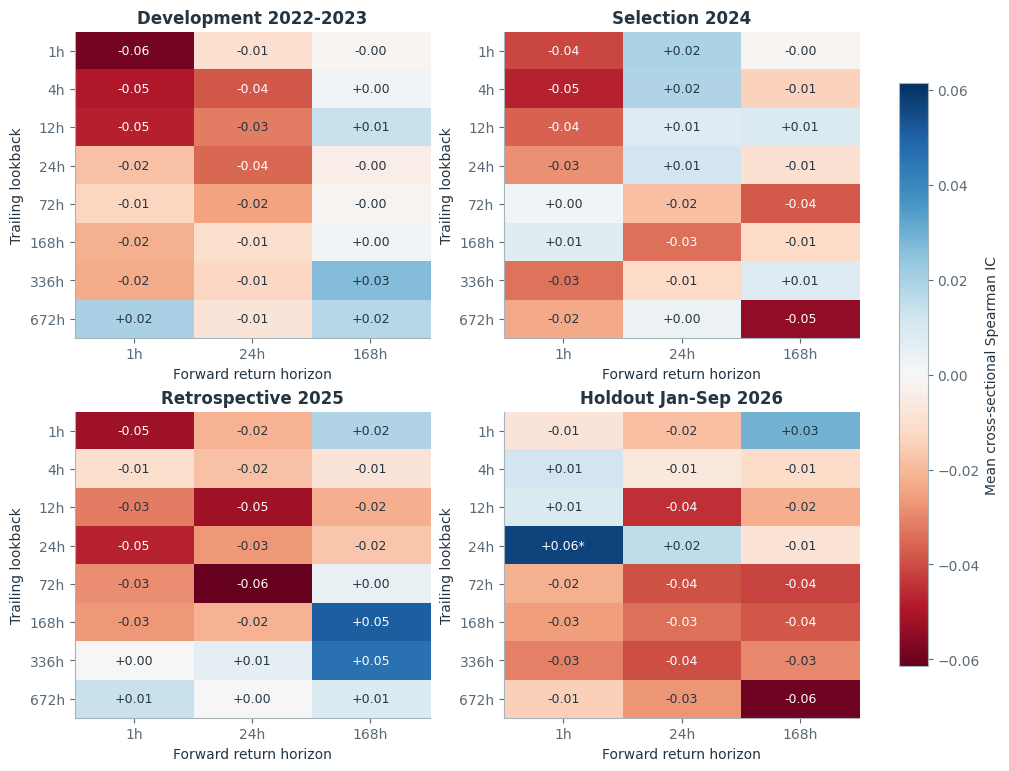

,split,lookback_h,forward_horizon_h,mean_ic,n_valid,ci_low,ci_high,p_holm
72,holdout,1,1,-0.00809,273,-0.06953,0.05515,1.00000
73,holdout,1,24,-0.01863,273,-0.07253,0.03394,1.00000
74,holdout,1,168,0.02915,267,-0.01656,0.07647,1.00000
75,holdout,4,1,0.01165,273,-0.02773,0.05398,1.00000
76,holdout,4,24,-0.00664,273,-0.05462,0.03693,1.00000
77,holdout,4,168,-0.01144,267,-0.07229,0.04705,1.00000
78,holdout,12,1,0.00904,273,-0.02853,0.04305,1.00000
79,holdout,12,24,-0.04467,273,-0.08535,-0.00113,0.95426
80,holdout,12,168,-0.02229,267,-0.07649,0.03035,1.00000
81,holdout,24,1,0.05681,273,0.01933,0.09516,0.04799


In [5]:
fig=plot_ic(d['ic_summary'])
plt.show()
ic_columns=['split','lookback_h','forward_horizon_h','mean_ic','n_valid','ci_low','ci_high','p_holm']
display(d['ic_summary'].loc[d['ic_summary'].split.eq('holdout'),ic_columns].round(5))

### 6. Historical screening

The CS buffer skips an entire rebalance below L1=0.25; Monday-weekly schedules are true calendar schedules. Trend weights remain at 1/8 per coin without rescaling active allocations. No 2025/2026 result selects a champion. The fixed residual model is a predeclared control, not tuned by 2024 Sharpe.

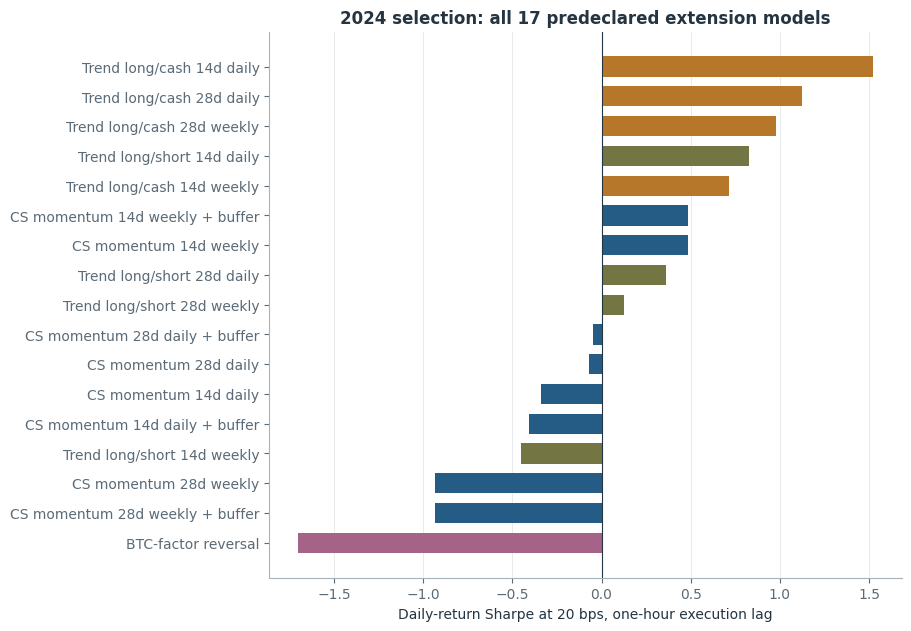

,strategy_id,total_return,sharpe,total_turnover
7,cross_momentum_h336_r168_b000,0.0910,0.4874,52.6250
10,cross_momentum_h336_r168_b025,0.0910,0.4874,52.6250
16,cross_momentum_h672_r024_b025,-0.0388,-0.0499,98.2500
13,cross_momentum_h672_r024_b000,-0.0432,-0.0693,105.6250
1,cross_momentum_h336_r024_b000,-0.1045,-0.3414,148.0000
4,cross_momentum_h336_r024_b025,-0.1193,-0.4061,145.1250
19,cross_momentum_h672_r168_b000,-0.2129,-0.9326,42.7500
22,cross_momentum_h672_r168_b025,-0.2129,-0.9332,42.7500
49,factor_residual_fixed,-0.0074,-1.7025,0.5714
25,trend_long_cash_h336_r024_b000,0.7460,1.5222,43.5000


,strategy_id,role,lookback_h,rebalance_h,buffer_l1
0,cross_momentum_h336_r168_b000,champion,336,168,0.0
1,trend_long_cash_h336_r024_b000,champion,336,24,0.0
2,trend_long_short_h336_r024_b000,champion,336,24,0.0
3,factor_residual_fixed,fixed_model,0,24,0.0
4,reference_original_momentum,original_reference,168,24,0.0
5,reference_original_reversal,original_reference,1,24,0.0
6,reference_scale_momentum,time_scale_reference,2160,168,0.0
7,reference_scale_reversal,time_scale_reference,672,168,0.0


In [6]:
fig=plot_screening(d['historical_metrics'])
plt.show()
validation=primary(d['historical_metrics'])
validation=validation.loc[validation.split.eq('validation')].sort_values(['family','sharpe'],ascending=[True,False])
display(validation[['strategy_id','total_return','sharpe','total_turnover']].round(4))
specs=pd.DataFrame(d['selection']['evaluated_strategies'])
display(specs[['strategy_id','role','lookback_h','rebalance_h','buffer_l1']])

### Historical yearly stability

These are retrospective matched calculations for the same eight frozen models, each year reset from cash and liquidated. The 2024 selection and already-viewed 2025 period are not independent tests. Yearly return changes do not establish their cause.

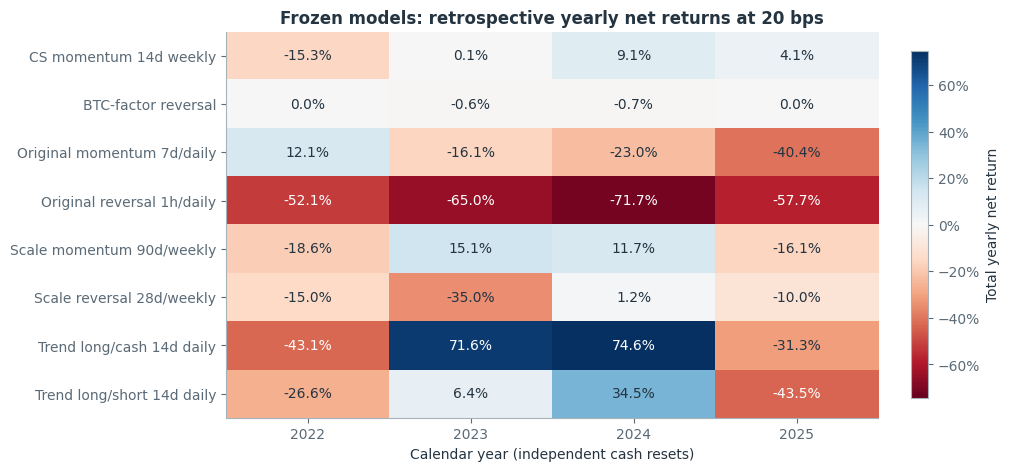

In [7]:
fig=plot_stability(d['annual_metrics'])
plt.show()

### 7. Frozen 2026 equity paths

All panels share the same equity scale. The initial unit capital is included. These paths summarize outcomes; do not use the displayed best performer as a new holdout-selected strategy.

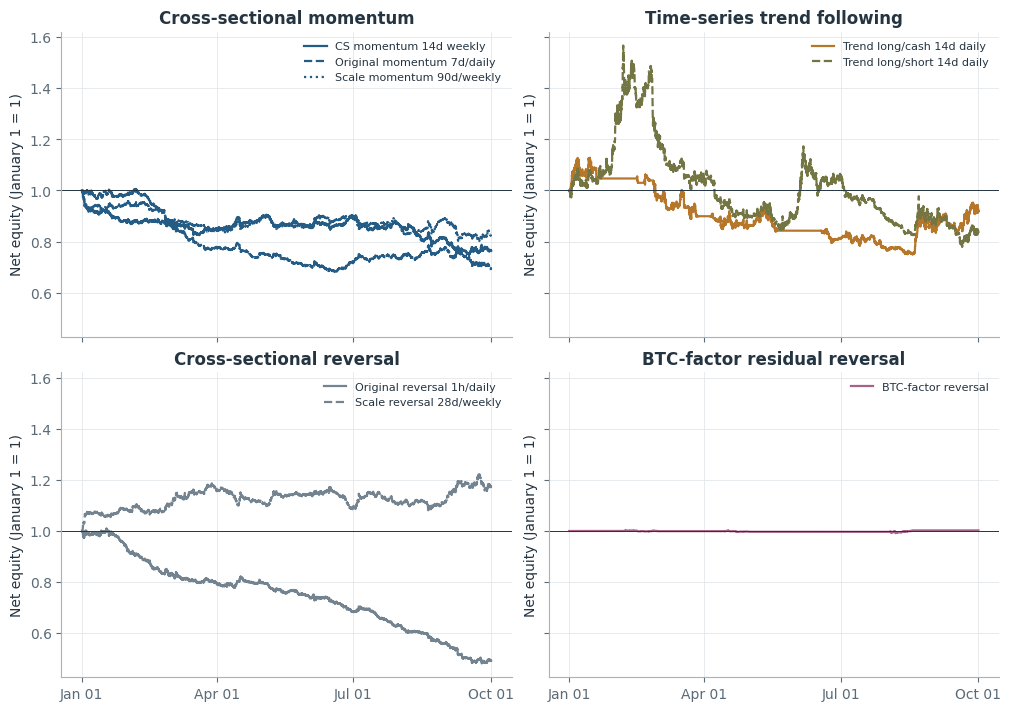

In [8]:
fig=plot_equity(d['returns'])
plt.show()

### 8. Cost and extra-delay stress

The same targets are evaluated at 0/5/10/15/20/40 bps and at 20 bps with lag two. Scenarios are not confidence intervals. Five bps total is below the course's assumed seven-bps commission alone.

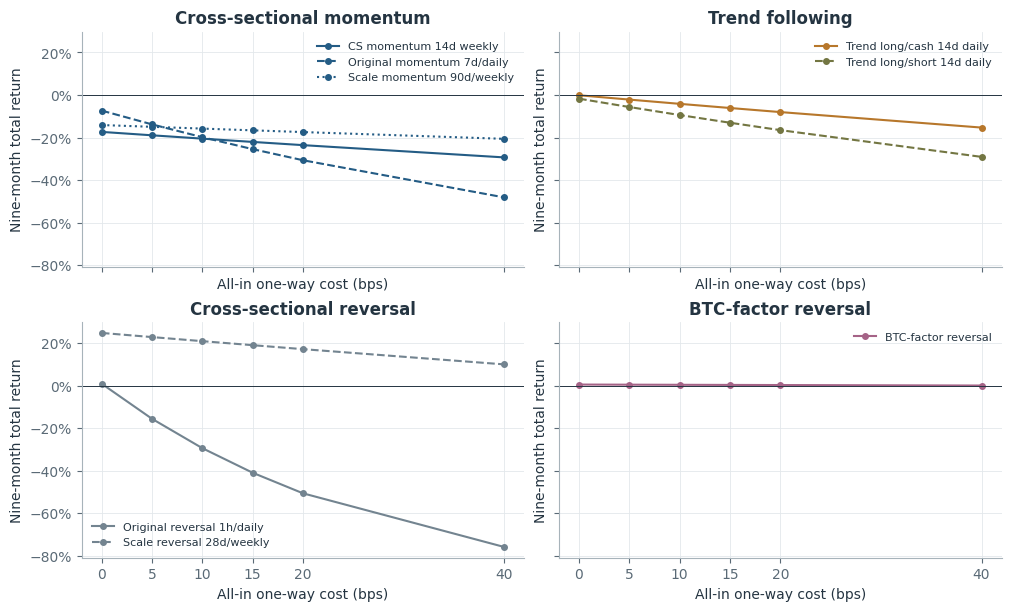

,strategy_id,execution_lag,total_return,sharpe,total_turnover
4,cross_momentum_h336_r168_b000,1,-0.23593,-2.21420,39.12500
6,cross_momentum_h336_r168_b000,2,-0.25997,-2.42984,39.12500
25,factor_residual_fixed,1,0.00229,0.31704,1.14286
27,factor_residual_fixed,2,0.00228,0.31456,1.14286
32,reference_original_momentum,1,-0.30698,-2.83518,145.00000
34,reference_original_momentum,2,-0.31615,-2.95768,145.37500
39,reference_original_reversal,1,-0.50682,-6.37636,357.03750
41,reference_original_reversal,2,-0.51246,-6.19193,358.53750
46,reference_scale_momentum,1,-0.17448,-1.35398,19.62500
48,reference_scale_momentum,2,-0.18361,-1.43291,19.62500


In [9]:
fig=plot_costs(d['holdout_metrics'])
plt.show()
lag=d['holdout_metrics'].loc[d['holdout_metrics'].cost_bps.eq(20)]
display(lag[['strategy_id','execution_lag','total_return','sharpe','total_turnover']].sort_values(['strategy_id','execution_lag']).round(5))

### 9. Factor model eligibility and actual trades

Monthly beta fitting uses the first 30 daily observations and spread calibration uses the following 60, all ending 24 hours before the refit decision. ADF Holm, beta and half-life gates may reject most coin-months. Monthly parameters remain frozen, first-day cash is forced, and same-day reentry is disallowed. Each spread's 1/7 budget includes its hedge; BTC legs are aggregated before costs. Raw logs retain October 1 terminal-boundary refits; they are excluded from Jan-Sep counts, and no earned holdout return uses the new terminal model.

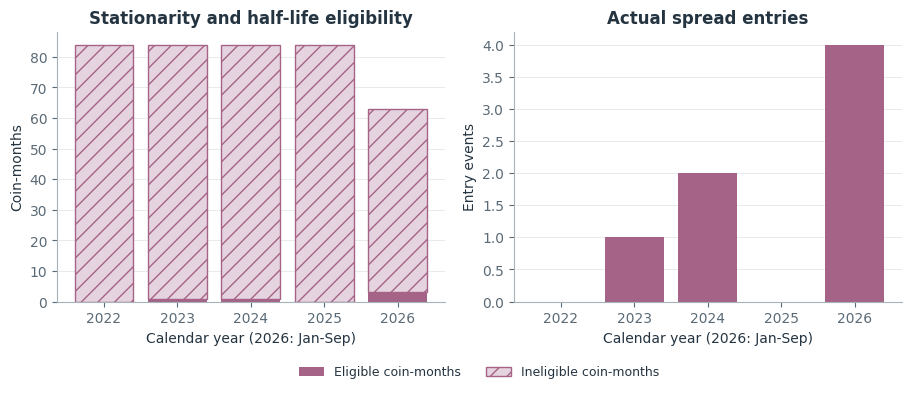

Raw model-log rows: 420; raw event-log rows: 459
Holdout: 63 coin-months; 3 eligible; 4 entries.


,refit_time,symbol,beta,half_life_days,adf_pvalue_holm,eligible,reason
399,2026-08-01 00:00:00+00:00,ETHUSDT,1.032292,17.300025,1.000000,False,adf_holm_not_rejected
400,2026-08-01 00:00:00+00:00,LTCUSDT,0.855849,2.754896,0.582345,False,adf_holm_not_rejected
401,2026-08-01 00:00:00+00:00,ADAUSDT,1.283592,3.565318,0.008095,True,eligible
402,2026-08-01 00:00:00+00:00,LINKUSDT,1.483481,2.315787,0.133449,False,adf_holm_not_rejected
403,2026-08-01 00:00:00+00:00,DOGEUSDT,1.007838,32.628091,1.000000,False,half_life_out_of_bounds;adf_holm_not_rejected
404,2026-08-01 00:00:00+00:00,DOTUSDT,1.242540,49.371504,1.000000,False,half_life_out_of_bounds;adf_holm_not_rejected
405,2026-08-01 00:00:00+00:00,SOLUSDT,1.238794,19.596323,1.000000,False,adf_holm_not_rejected
406,2026-09-01 00:00:00+00:00,ETHUSDT,1.343394,3.116754,0.359229,False,adf_holm_not_rejected
407,2026-09-01 00:00:00+00:00,LTCUSDT,0.901399,179.681096,1.000000,False,half_life_out_of_bounds;adf_holm_not_rejected
408,2026-09-01 00:00:00+00:00,ADAUSDT,1.561285,46.252120,1.000000,False,half_life_out_of_bounds;adf_holm_not_rejected


,decision_time,symbol,event,z,side,prior_side,holding_days,model_refit_time
440,2026-08-01 00:00:00+00:00,DOGEUSDT,monthly_refit_cash,NaN,0,0,0,2026-08-01 00:00:00+00:00
441,2026-08-01 00:00:00+00:00,DOTUSDT,monthly_refit_cash,NaN,0,0,0,2026-08-01 00:00:00+00:00
442,2026-08-01 00:00:00+00:00,SOLUSDT,monthly_refit_cash,NaN,0,0,0,2026-08-01 00:00:00+00:00
443,2026-08-03 00:00:00+00:00,ADAUSDT,entry,2.058757,-1,0,0,2026-08-01 00:00:00+00:00
444,2026-08-18 00:00:00+00:00,ADAUSDT,mean_reversion_exit,0.393952,0,-1,15,2026-08-01 00:00:00+00:00
445,2026-09-01 00:00:00+00:00,ETHUSDT,monthly_refit_cash,NaN,0,0,0,2026-09-01 00:00:00+00:00
446,2026-09-01 00:00:00+00:00,LTCUSDT,monthly_refit_cash,NaN,0,0,0,2026-09-01 00:00:00+00:00
447,2026-09-01 00:00:00+00:00,ADAUSDT,monthly_refit_cash,NaN,0,0,0,2026-09-01 00:00:00+00:00
448,2026-09-01 00:00:00+00:00,LINKUSDT,monthly_refit_cash,NaN,0,0,0,2026-09-01 00:00:00+00:00
449,2026-09-01 00:00:00+00:00,DOGEUSDT,monthly_refit_cash,NaN,0,0,0,2026-09-01 00:00:00+00:00


In [10]:
fig=plot_factor(d['factor_models'], d['factor_events'])
plt.show()
print(f"Raw model-log rows: {len(d['factor_models'])}; raw event-log rows: {len(d['factor_events'])}")
model_columns=['refit_time','symbol','beta','half_life_days','adf_pvalue_holm','eligible','reason']
model_time=pd.to_datetime(d['factor_models'].refit_time,utc=True)
event_time=pd.to_datetime(d['factor_events'].decision_time,utc=True)
holdout_models=d['factor_models'].loc[model_time.ge(pd.Timestamp('2026-01-01',tz='UTC')) & model_time.lt(pd.Timestamp('2026-10-01',tz='UTC'))]
holdout_events=d['factor_events'].loc[event_time.ge(pd.Timestamp('2026-01-01',tz='UTC')) & event_time.lt(pd.Timestamp('2026-10-01',tz='UTC'))]
assert len(holdout_models)==63
print('Holdout:',len(holdout_models),'coin-months;',int(holdout_models.eligible.sum()),'eligible;',int(holdout_events.event.eq('entry').sum()),'entries.')
display(holdout_models[model_columns].tail(14))
display(holdout_events.tail(12))

### 10. Descriptive following-day regimes

High/low medians are fit on development only. Unknowns remain unknown. High-minus-low mean daily-return contrasts and bootstrap intervals show association, not causation. Holm adjustment is within period across declared regime contrasts. No discontinuous regime Sharpe or trading gate is introduced.

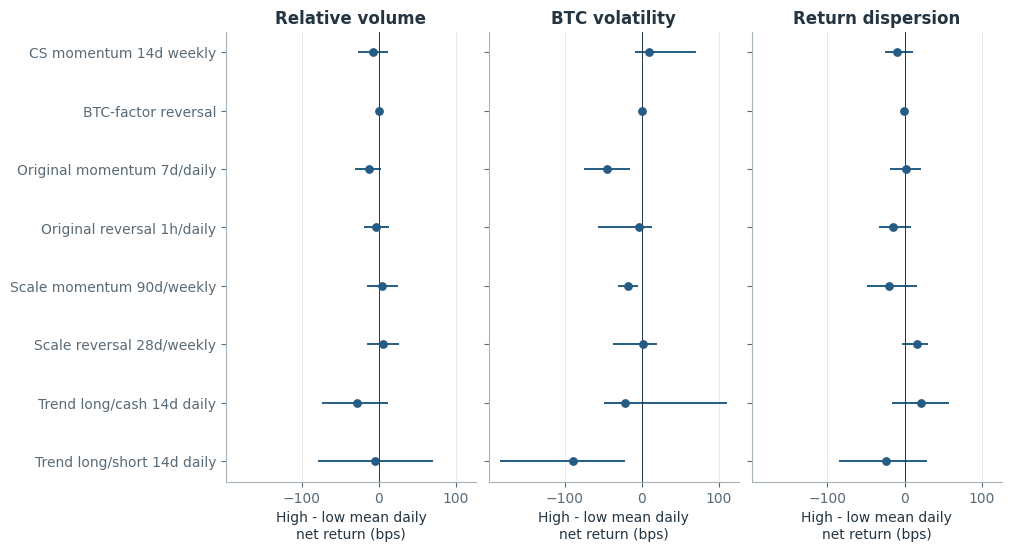

,strategy_id,feature,high_minus_low_net_return,ci_low,ci_high,p_holm
216,cross_momentum_h336_r168_b000,relative_quote_volume,-0.00076,-0.00274,0.00118,1.00000
219,cross_momentum_h336_r168_b000,btc_volatility_30d,0.00091,-0.00085,0.00707,1.00000
222,cross_momentum_h336_r168_b000,return_dispersion_24h,-0.00093,-0.00260,0.00112,1.00000
225,factor_residual_fixed,relative_quote_volume,0.00002,-0.00008,0.00011,1.00000
228,factor_residual_fixed,btc_volatility_30d,-0.00002,-0.00010,0.00007,1.00000
231,factor_residual_fixed,return_dispersion_24h,-0.00008,-0.00022,0.00001,1.00000
234,reference_original_momentum,relative_quote_volume,-0.00129,-0.00312,0.00035,1.00000
237,reference_original_momentum,btc_volatility_30d,-0.00446,-0.00747,-0.00146,0.21736
240,reference_original_momentum,return_dispersion_24h,0.00016,-0.00186,0.00208,1.00000
243,reference_original_reversal,relative_quote_volume,-0.00030,-0.00194,0.00129,1.00000


Calendar_days  Min_valid_returns  \
feature               regime                                      
btc_volatility_30d    high                58                 58   
                      low                215                215   
                      unknown              0                  0   
relative_quote_volume high               139                139   
                      low                134                134   
                      unknown              0                  0   
return_dispersion_24h high                70                 70   
                      low                203                203   
                      unknown              0                  0   

                               Max_valid_returns  
feature               regime                      
btc_volatility_30d    high                    58  
                      low                    215  
                      unknown                  0  
relative_quote_volume high                   139  
                      low                    134  
                      unknown                  0  
return_dispersion_24h high                    70  
                      low                    203  
                      unknown                  0

Counts are shared calendar regimes; min/max preserve possible model-level return availability differences. Full conditional model means/turnover are retained in regime_summary.csv.
Holm-corrected significant contrasts: 0 of 24.


In [11]:
fig=plot_regimes(d['regime_summary'])
plt.show()
regime=d['regime_summary'].loc[d['regime_summary'].split.eq('holdout')]
contrast_columns=[c for c in ['strategy_id','feature','high_minus_low_net_return','ci_low','ci_high','p_holm'] if c in regime]
display(regime.drop_duplicates(['strategy_id','feature'])[contrast_columns].round(5))
counts=regime.groupby(['feature','regime']).agg(Calendar_days=('n_days','first'),Min_valid_returns=('n_valid_returns','min'),Max_valid_returns=('n_valid_returns','max'))
display(counts)
print('Counts are shared calendar regimes; min/max preserve possible model-level return availability differences. Full conditional model means/turnover are retained in regime_summary.csv.')
print('Holm-corrected significant contrasts:',int(regime.drop_duplicates(['strategy_id','feature']).p_holm.lt(.05).sum()),'of 24.')

## Takeaways

- 2 of 8 frozen evaluations had positive 20 bps net returns during January-September 2026. The three 2024-selected extension champions all had negative net returns: Trend long/cash 14d daily -8.04%, Trend long/short 14d daily -16.53%, CS momentum 14d weekly -23.59%.

- Scale reversal 28d/weekly had the highest observed net return, 17.11%, with Sharpe 1.53. This is a preserved reference-model result, not a post-holdout selection.

- Fixed BTC-factor reversal returned 0.23% net from only 4 spread entries. Sparse activity does not establish a persistent profitable edge.

- 1 of 24 holdout signal comparisons passed the within-period Holm 5% threshold. Correlations are diagnostic, not independent strategy profits.

No claim of risk-free arbitrage or deployable edge is established by a historical backtest alone. Original research is preserved; this is a separate extension. Successful and unsuccessful configurations are retained. New tests after viewing these outcomes must be labeled exploratory and evaluated on further unexamined/prospective data.

## Sources and reproduction

- [Binance archive documentation](https://github.com/binance/binance-public-data)
- [Binance dataset terms](https://github.com/binance/binance-public-data/blob/master/TERMS_AND_CONDITIONS.md)
- [Official 2023 halt account](https://www.binance.com/en/blog/from-our-ceo/6789340645608890113)
- Assignment: `/Users/cosdis/Downloads/quant_course/ClassProject.docx`

Binance data and dataset-derived charts/results are attributed to Binance under the stated CC BY-NC-SA 4.0 non-commercial educational/personal non-production terms. Source archives, checksums, normalizations, analysis freeze, selections and output hashes accompany the separate project. No live orders, publication, or scheduled monitoring.

Regenerate artifacts without downloading or tuning: `python -m crypto_stat_arb_extensions report`. Run tests: `python -m pytest -q`.